# Exploratory Data Analysis — Give Me Some Credit

This notebook explores the **training split** of the *Give Me Some Credit* dataset
(Kaggle). The goal is to understand each variable, check data quality and measure how
well each variable separates good payers from defaulters, including its
**Information Value (IV)**.

Only the 10 original variables are analysed here. The analysis is done on the training
split only, so that validation and test data do not influence any decision.
No imputation is applied at this stage: missing values are kept as `NaN`.

**Sections**
0. Setup and data loading
1. Overview
2. Data quality
3. Univariate analysis
4. Default rate by bin
5. Information Value
6. Correlation and redundancy
7. Summary

## 0. Setup and data loading

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from src import config, eda_utils, split_data

%matplotlib inline
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

The training split already uses the short variable names (they are set in the
split step), with `ID` as the first column. The original Kaggle names are listed
in the data dictionary below.

In [2]:
train = pd.read_csv(config.SPLIT_TRAIN, index_col='ID')

# Check that the file has exactly the expected columns
EXPECTED_COLUMNS = ['Default', 'Util', 'Age', 'Late30_59', 'Debt', 'Income',
                    'OpenCred', 'Late90', 'RealEstate', 'Late60_89', 'No.Dep']
assert train.columns.to_list() == EXPECTED_COLUMNS, train.columns.to_list()

train.head()

,Default,Util,Age,Late30_59,Debt,Income,OpenCred,Late90,RealEstate,Late60_89,No.Dep
ID,,,,,,,,,,,
138986,0,0.000000,49,0,0.127227,5163.0,5,0,0,0,0.0
63965,0,0.033105,37,0,0.423063,2800.0,4,0,1,0,1.0
46078,0,0.007948,39,0,0.685663,3333.0,11,0,1,0,0.0
83031,0,0.576297,57,0,0.320077,15161.0,14,0,4,0,0.0
11185,0,0.623724,35,0,0.534226,6500.0,9,0,3,0,1.0


### Data dictionary

| Variable | Original Kaggle name | Description |
|---|---|---|
| `Default` | `SeriousDlqin2yrs` | Target: serious delinquency (90+ days past due) in the next 2 years (1 = default, 0 = no default) |
| `Util` | `RevolvingUtilizationOfUnsecuredLines` | Credit utilisation ratio (revolving balance / credit limit) |
| `Age` | `age` | Age of the borrower in years |
| `Late30_59` | `NumberOfTime30-59DaysPastDueNotWorse` | Number of times the borrower was 30–59 days past due |
| `Debt` | `DebtRatio` | Debt-to-income ratio (monthly debt payments / monthly income) |
| `Income` | `MonthlyIncome` | Monthly income of the borrower |
| `OpenCred` | `NumberOfOpenCreditLinesAndLoans` | Number of open credit lines and loans |
| `Late90` | `NumberOfTimes90DaysLate` | Number of times the borrower was 90+ days past due |
| `RealEstate` | `NumberRealEstateLoansOrLines` | Number of mortgage and real estate loans |
| `Late60_89` | `NumberOfTime60-89DaysPastDueNotWorse` | Number of times the borrower was 60–89 days past due |
| `No.Dep` | `NumberOfDependents` | Number of dependents in the borrower's household |

## 1. Overview

In [3]:
print(f'Data shape (n_rows, n_columns): {train.shape}')
train.info()

Data shape (n_rows, n_columns): (105000, 11)
<class 'pandas.DataFrame'>
Index: 105000 entries, 138986 to 80531
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Default     105000 non-null  int64  
 1   Util        105000 non-null  float64
 2   Age         105000 non-null  int64  
 3   Late30_59   105000 non-null  int64  
 4   Debt        105000 non-null  float64
 5   Income      84277 non-null   float64
 6   OpenCred    105000 non-null  int64  
 7   Late90      105000 non-null  int64  
 8   RealEstate  105000 non-null  int64  
 9   Late60_89   105000 non-null  int64  
 10  No.Dep      102279 non-null  float64
dtypes: float64(4), int64(7)
memory usage: 9.6 MB


In [4]:
# Overall default rate: the baseline for every comparison in this notebook
default_rate = train['Default'].mean()
print(f'Default rate: {default_rate*100:.2f}%')
train['Default'].value_counts()

Default rate: 6.68%


Default
0    97982
1     7018
Name: count, dtype: int64

The target is imbalanced: defaulters are a small minority. Default rates by bin
(Section 4) should always be read against this overall rate.

## 2. Data quality

Points checked here:
- missing values and whether missingness is related to default;
- special codes in the late-payment variables (values such as 96 and 98);
- implausible ages (e.g. `Age = 0`);
- extreme values in `Util` and `Debt` (to be confirmed).
- duplicate rows (checked on the raw data, before the split).

### 2.1 Missing values

In [5]:
eda_utils.missing_values_statistics(train)

------------------------------------------------------------------------------------------------------------------------------------------------------
Statistical analysis of missing values by column

Column Income:
  Missing rows: 20723 (19.7%)
  Default rate (non-missing): 7.0%
  Default rate (missing):     5.5%

Column No.Dep:
  Missing rows: 2721 (2.6%)
  Default rate (non-missing): 6.8%
  Default rate (missing):     4.2%


Both columns with missing values show a lower default rate when the value is missing.
Since the two may be related, the next cell checks whether the rows with missing
`No.Dep` are the same rows with missing `Income`.

In [6]:
# Are the rows with missing No.Dep also missing Income?
both = train['No.Dep'].isna() & train['Income'].isna()
print(f"Rows missing No.Dep: {train['No.Dep'].isna().sum()}")
print(f"  of which also missing Income: {both.sum()}")

Rows missing No.Dep: 2721
  of which also missing Income: 2721


*Notes:*
- **Income** is missing for 19.7% of the clients. Their default rate is lower
  (5.5% vs 7.0%), so missingness is informative.
- **No.Dep** is missing for 2.6% of the clients, with an even lower default rate
  (4.2% vs 6.8%).
- All 2,721 rows with missing `No.Dep` also have missing `Income`: this is a single
  group of clients with incomplete records, not two separate issues.
- Median imputation (applied later, in processing) would erase this signal. Although
  the IV of the `Missing` bin is small (0.008 for Income, 0.005 for No.Dep; see the
  tables in Section 4), a missing flag for `Income` is created alongside the
  imputation, since it also identifies the clients for whom Debt is not a ratio.

### 2.2 Special codes in the late-payment variables

In [7]:
# Counts above ~20 are not plausible for 2 years of history; list them
late_cols = ['Late30_59', 'Late60_89', 'Late90']

for column in late_cols:
    high = train.loc[train[column] > 20, column]
    print(f'{column}: {len(high)} rows above 20 -> values {sorted(high.unique().tolist())}')

Late30_59: 182 rows above 20 -> values [96, 98]
Late60_89: 182 rows above 20 -> values [96, 98]
Late90: 182 rows above 20 -> values [96, 98]


Two special codes were found: 96 and 98. The next cell checks whether they appear in
the same rows for the three late-payment variables, and compares the default rate of
these rows with the overall default rate.

In [8]:
# Do the special codes appear in the same rows for the three variables?
special = train[late_cols] > 20
print('Rows with a special code in each variable:')
print(special.sum())
print(f'Rows with a special code in all three: {special.all(axis=1).sum()}')

# Default rate of the rows with special codes
print(f"Default rate in these rows: {train.loc[special.any(axis=1), 'Default'].mean()*100:.1f}%")

Rows with a special code in each variable:
Late30_59    182
Late60_89    182
Late90       182
dtype: int64
Rows with a special code in all three: 182
Default rate in these rows: 54.4%


*Notes:*
- The codes 96 and 98 appear in the same 182 rows for the three late-payment
  variables: they flag the whole record, not three independent counts.
- The default rate of these rows is 54.4%, about 8 times the overall rate.
  The group is small (under 0.2% of the clients) but very high risk.
- The meaning of the codes is not documented, but they carry a strong risk signal and
  should not be discarded. In Section 4 they get their own bin (`96/98`), so they do
  not distort the `5-20` bin. In processing, these rows get a flag and the
  codes are replaced by the median (0), so they are not read as counts.

### 2.3 Implausible ages

In [9]:
print(f"Rows with Age < 18: {(train['Age'] < 18).sum()}")
train.loc[train['Age'] < 18]

Rows with Age < 18: 0


,Default,Util,Age,Late30_59,Debt,Income,OpenCred,Late90,RealEstate,Late60_89,No.Dep
ID,,,,,,,,,,,


*Notes:* no implausible ages in the training split; the minimum age is 21.

### 2.4 Extreme values in Util and Debt

In [10]:
# Util is a ratio expected to be mostly between 0 and 1
print(f"Share of Util > 1:  {(train['Util'] > 1).mean()*100:.2f}%")
print(f"Share of Util > 10: {(train['Util'] > 10).mean()*100:.2f}%")

# Debt: share above 10 and how often income is missing in that group
debt_high = train['Debt'] > 10
print(f'Share of Debt > 10: {debt_high.mean()*100:.2f}%')
print(f"Income missing when Debt > 10: {train.loc[debt_high, 'Income'].isna().mean()*100:.1f}%")
print(f"Default rate when Debt > 10:  {train.loc[debt_high, 'Default'].mean()*100:.1f}%")
print(f"Default rate when Debt <= 10: {train.loc[~debt_high, 'Default'].mean()*100:.1f}%")

Share of Util > 1:  2.21%
Share of Util > 10: 0.16%
Share of Debt > 10: 19.18%
Income missing when Debt > 10: 92.6%
Default rate when Debt > 10:  5.4%
Default rate when Debt <= 10: 7.0%


*Notes:*
- **Util:** 2.21% of the clients have Util > 1, which is possible (balance above the
  credit limit). Only 0.16% have Util > 10, which is implausible as a ratio and is
  likely a recording error or a different unit. Section 4 shows that their default
  rate is close to the average, so they are treated as invalid values in processing.
- **Debt:** 19.18% of the clients have Debt > 10, and 92.6% of them have missing
  Income. Without income, the ratio cannot be computed and the column seems to hold
  the debt amount instead. Debt therefore mixes two different measures: a ratio for
  clients with income and an absolute value for clients without it.
- The default rate for Debt > 10 (5.4% vs 7.0%) mirrors the missing-Income group:
  high Debt values mostly reflect missing income, not heavy indebtedness.

In [11]:
eda_utils.quantile_analysis(train[['Util', 'Debt']])

----------------------------------------------------------------------------------------------------
Quantile analysis by column

Column Util:
0.900       0.980808
0.950       1.000000
0.995       1.380921
0.999    1655.020000
Column Debt:
0.900     1270.000
0.950     2444.050
0.995     6211.020
0.999    10924.006


- **Quantiles:** for Util, values are plausible up to the 99.5% quantile (1.38) and
  then jump to 1,655 at 99.9%, so the extreme values are a small, separate group.
  For Debt there is no jump but a long continuous tail (1,270 at the 90% quantile),
  consistent with debt amounts recorded for clients without income.

### 2.5 Duplicate rows

This is the only check in this notebook that uses the full raw dataset instead of the
training split. Duplicates must be counted before the train / validation / test split:
copies of the same row can end up in different splits, which the training split alone
cannot show. No statistic is learned from the raw data here; only the number of
duplicate rows is returned. The raw data is accessed only through `src.split_data`.

Rows are compared on all columns except `ID`.

In [12]:
n_duplicates = split_data.count_raw_duplicates()
print(f"Exact duplicate rows in the raw data: {n_duplicates} ({n_duplicates / 150_000:.2%})")

Exact duplicate rows in the raw data: 609 (0.41%)


*Notes:* 609 rows (0.41%) are exact duplicates of another row. They are kept in the
dataset: most of them are sparse profiles (no debt, missing income), which different
clients can share.

## 3. Univariate analysis

In [13]:
eda_utils.get_statistics(train, step=5)

Statistics for columns 0 to 5
             Default           Util            Age      Late30_59           Debt
count  105000.000000  105000.000000  105000.000000  105000.000000  105000.000000
mean        0.066838       6.482739      52.277657       0.415752     355.053748
std         0.249743     267.781319      14.760952       4.125424    2200.062016
min         0.000000       0.000000      21.000000       0.000000       0.000000
25%         0.000000       0.029642      41.000000       0.000000       0.175949
50%         0.000000       0.153553      52.000000       0.000000       0.367554
75%         0.000000       0.560096      63.000000       0.000000       0.861211
max         1.000000   50708.000000     109.000000      98.000000  329664.000000
Statistics for columns 5 to 10
             Income       OpenCred         Late90     RealEstate      Late60_89
count  8.427700e+04  105000.000000  105000.000000  105000.000000  105000.000000
mean   6.613049e+03       8.466371       0.260752 

In [14]:
# Upper quantiles of every variable, to spot heavy right tails
eda_utils.quantile_analysis(train.drop(columns='Default'))

----------------------------------------------------------------------------------------------------
Quantile analysis by column

Column Util:
0.900       0.980808
0.950       1.000000
0.995       1.380921
0.999    1655.020000
Column Age:
0.900    72.0
0.950    78.0
0.995    89.0
0.999    94.0
Column Late30_59:
0.900     1.0
0.950     2.0
0.995     5.0
0.999    98.0
Column Debt:
0.900     1270.000
0.950     2444.050
0.995     6211.020
0.999    10924.006
Column Income:
0.900    11600.0
0.950    14583.0
0.995    35000.0
0.999    78000.0
Column OpenCred:
0.900    15.0
0.950    18.0
0.995    27.0
0.999    35.0
Column Late90:
0.900     0.0
0.950     1.0
0.995     4.0
0.999    98.0
Column RealEstate:
0.900    2.0
0.950    3.0
0.995    6.0
0.999    9.0
Column Late60_89:
0.900     0.0
0.950     1.0
0.995     2.0
0.999    98.0
Column No.Dep:
0.900    2.0
0.950    3.0
0.995    5.0
0.999    6.0


In [15]:
# Proportion of each value, only for the count variables
# (continuous variables have too many distinct values for this view)
count_cols = ['Late30_59', 'Late60_89', 'Late90', 'RealEstate', 'No.Dep']
eda_utils.get_data_proportion(train[count_cols])

------------------------------------------------------------------------------------------------------------------------------------------------------
Proportion of values in each column
Column Late30_59:
 Late30_59
0     0.839790
1     0.107162
2     0.030714
3     0.011933
4     0.004790
5     0.002238
6     0.000933
7     0.000352
8     0.000200
9     0.000086
10    0.000038
11    0.000010
12    0.000010
13    0.000010
96    0.000010
98    0.001724
Name: proportion, dtype: float64
Column Late60_89:
 Late60_89
0     0.949162
1     0.038562
2     0.007305
3     0.002114
4     0.000705
5     0.000248
6     0.000105
7     0.000057
11    0.000010
96    0.000010
98    0.001724
Name: proportion, dtype: float64
Column Late90:
 Late90
0     0.943838
1     0.035457
2     0.010419
3     0.004495
4     0.002076
5     0.000829
6     0.000524
7     0.000229
8     0.000143
9     0.000105
10    0.000057
11    0.000019
12    0.000010
13    0.000029
14    0.000010
15    0.000019
17    0.000010
96    

In [16]:
# Statistics for defaulters only, to compare with the whole data
defaulter = train[train['Default'] == 1]
eda_utils.defaulter_statistics(defaulter)

----------------------------------------------------------------------------------------------------
Defaulter's statistics:
Statistics for columns 0 to 5
       Default         Util          Age    Late30_59          Debt
count   7018.0  7018.000000  7018.000000  7018.000000   7018.000000
mean       1.0     5.053576    46.113565     2.327301    280.827590
std        0.0   139.184235    12.929218    11.521610   1167.434426
min        1.0     0.000000    21.000000     0.000000      0.000000
25%        1.0     0.402497    36.000000     0.000000      0.196757
50%        1.0     0.833720    46.000000     0.000000      0.426536
75%        1.0     1.000000    55.000000     2.000000      0.869548
max        1.0  8328.000000   101.000000    98.000000  32843.000000
Statistics for columns 5 to 10
              Income     OpenCred       Late90   RealEstate    Late60_89
count    5882.000000  7018.000000  7018.000000  7018.000000  7018.000000
mean     5618.088575     7.860359     2.047449     0.986

*Notes:*
- For several variables the mean is not representative, because of the issues seen
  in Section 2:
  - **Util:** mean 6.48 vs median 0.15, driven by a small group of extreme values.
  - **Debt:** mean 355 vs median 0.37, driven by the debt amounts recorded for
    clients without income.
  - **Late variables:** standard deviation around 4 and maximum 98, driven by the
    special codes; the median and the 75% quantile are 0.
  Medians and quantiles describe the typical client better than means here.
- **Income** has a long right tail (median 5,382; 99.9% quantile 78,000; maximum about
  1.79 million) and some clients with income equal to 0.
- **Upper quantiles:** Age and No.Dep have plausible tails (99.9% quantiles of 94 and
  6). For the late-payment variables, the 99.5% quantile is still a real count (5 for
  Late30_59), while the 99.9% quantile is already the special code 98.
- **Defaulters vs. all clients:** defaulters are younger (median age 46 vs 52), use
  more of their credit (median Util 0.83 vs 0.15) and have lower income (median
  4,500 vs 5,382).

## 4. Default rate by bin

Each variable is cut into ranges. For each range, the plot shows the **number of
clients** (bars) and the **default rate** (line). The dashed line is the overall
default rate.

Notes on the bins:
- Count variables start at `-1`, so that `0` gets its own bin (`(-1, 0]`).
- `Util` and `Debt` are ratios, so the bins are fractions (the labels show %).
- `Income` is in currency units.
- Missing values get their own `Missing` bin.
- These bins are an analytical choice and may be adjusted if a bin has too few clients.

In [17]:
# Bin edges and labels for each variable: used for the plots and for the IV
BINS = {
    'Util': {
        'bins': [0, 0.1, 0.2, 0.5, 0.75, 0.95, 1, 1.5, 2, 5, float('inf')],
        'labels': ['0-10%', '10-20%', '20-50%', '50-75%', '75-95%', '95-100%',
                   '100-150%', '150-200%', '200-500%', '>500%'],
    },
    'Age': {
        'bins': [20, 25, 30, 40, 50, 60, 70, float('inf')],
        'labels': ['21-25', '26-30', '31-40', '41-50', '51-60', '61-70', '71+'],
    },
    'Late30_59': {
        'bins': [-1, 0, 1, 2, 3, 4, 20, float('inf')],
        'labels': ['0', '1', '2', '3', '4', '5-20', '96/98'],

    },
    'Debt': {
        'bins': [0, 0.1, 0.2, 0.5, 0.75, 1, 1.5, 2, 5, 10, float('inf')],
        'labels': ['0-10%', '10-20%', '20-50%', '50-75%', '75-100%', '100-150%',
                   '150-200%', '200-500%', '500-1000%', '>1000%'],
    },
    'Income': {
        'bins': [0, 1e3, 2e3, 4e3, 6e3, 8e3, 10e3, 15e3, 20e3, 50e3, float('inf')],
        'labels': ['0-1k', '1-2k', '2-4k', '4-6k', '6-8k', '8-10k', '10-15k',
                   '15-20k', '20-50k', '50k+'],
    },
    'OpenCred': {
        'bins': [0, 5, 10, 15, 20, 25, float('inf')],
        'labels': ['0-5', '6-10', '11-15', '16-20', '21-25', '26+'],
    },
    'Late90': {
        'bins': [-1, 0, 1, 2, 3, 4, 20, float('inf')],
        'labels': ['0', '1', '2', '3', '4', '5-20', '96/98'],

    },
    'RealEstate': {
        'bins': [-1, 0, 1, 2, 3, float('inf')],
        'labels': ['0', '1', '2', '3', '4+'],
    },
    'Late60_89': {
        'bins': [-1, 0, 1, 2, 3, 4, 20, float('inf')],
        'labels': ['0', '1', '2', '3', '4', '5-20', '96/98'],

    },
    'No.Dep': {
        'bins': [-1, 0, 1, 2, 3, 4, 5, float('inf')],
        'labels': ['0', '1', '2', '3', '4', '5', '6+'],
    },
}


Util


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
Util,,,,,,,
0-10%,45182,835,0.018,0.453,0.119,1.335,0.445
10-20%,12022,311,0.026,0.120,0.044,0.991,0.074
20-50%,18876,924,0.049,0.183,0.132,0.330,0.017
50-75%,9704,1015,0.105,0.089,0.145,-0.490,0.027
75-95%,7225,1194,0.165,0.062,0.170,-1.017,0.110
95-100%,9669,1878,0.194,0.080,0.268,-1.214,0.228
100-150%,1889,741,0.392,0.012,0.106,-2.199,0.207
150-200%,173,76,0.439,0.001,0.011,-2.394,0.024
200-500%,83,26,0.313,0.001,0.004,-1.862,0.006


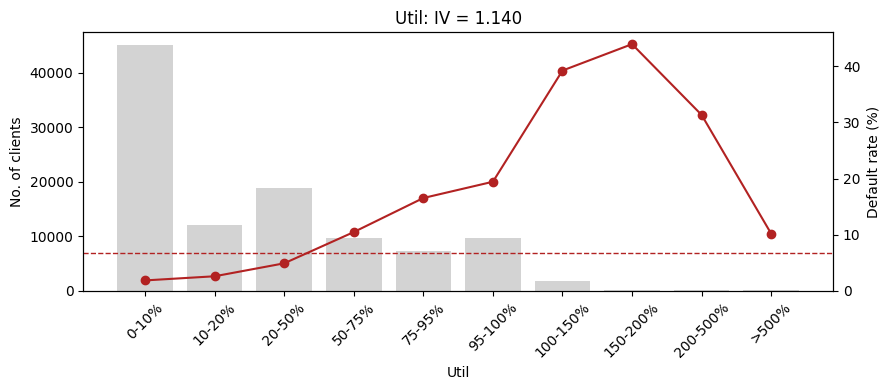


Age


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
Age,,,,,,,
21-25,2169,234,0.108,0.020,0.033,-0.526,0.007
26-30,5383,616,0.114,0.049,0.088,-0.591,0.023
31-40,17028,1668,0.098,0.157,0.238,-0.416,0.034
41-50,24533,2009,0.082,0.230,0.286,-0.220,0.012
51-60,24419,1514,0.062,0.234,0.216,0.080,0.001
61-70,19179,684,0.036,0.189,0.097,0.660,0.060
71+,12289,293,0.024,0.122,0.042,1.074,0.087


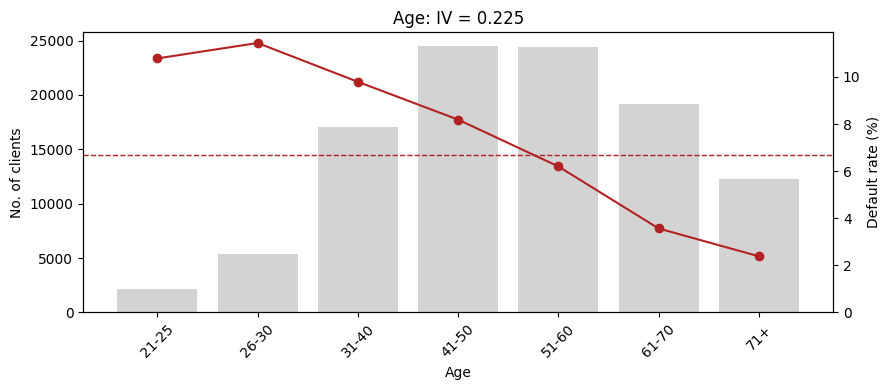


Late30_59


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
Late30_59,,,,,,,
0,88178,3560,0.040,0.864,0.507,0.532,0.190
1,11252,1660,0.148,0.098,0.237,-0.882,0.122
2,3225,866,0.269,0.024,0.123,-1.635,0.162
3,1253,429,0.342,0.008,0.061,-1.984,0.105
4,503,219,0.435,0.003,0.031,-2.377,0.067
5-20,407,185,0.455,0.002,0.026,-2.454,0.059
96/98,182,99,0.544,0.001,0.014,-2.812,0.037


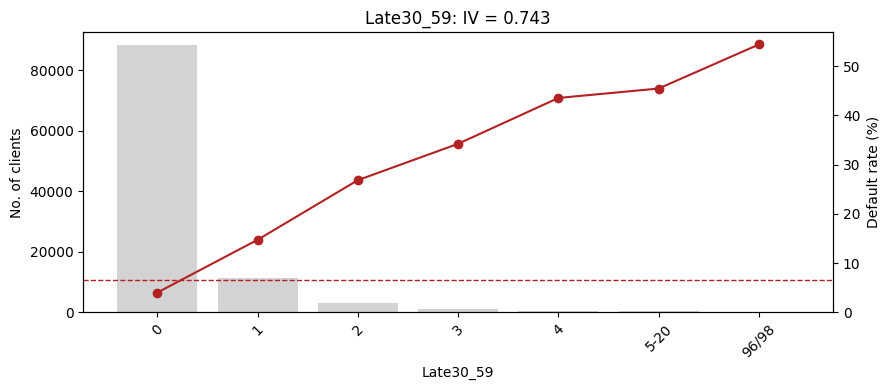


Debt


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
Debt,,,,,,,
0-10%,17170,1011,0.059,0.165,0.144,0.135,0.003
10-20%,12365,777,0.063,0.118,0.111,0.065,0.000
20-50%,36086,2176,0.060,0.346,0.310,0.110,0.004
50-75%,11087,1062,0.096,0.102,0.151,-0.392,0.019
75-100%,3793,425,0.112,0.034,0.061,-0.567,0.015
100-150%,2166,296,0.137,0.019,0.042,-0.794,0.018
150-200%,718,87,0.121,0.006,0.012,-0.660,0.004
200-500%,941,68,0.072,0.009,0.010,-0.091,0.000
500-1000%,539,24,0.045,0.005,0.003,0.410,0.001


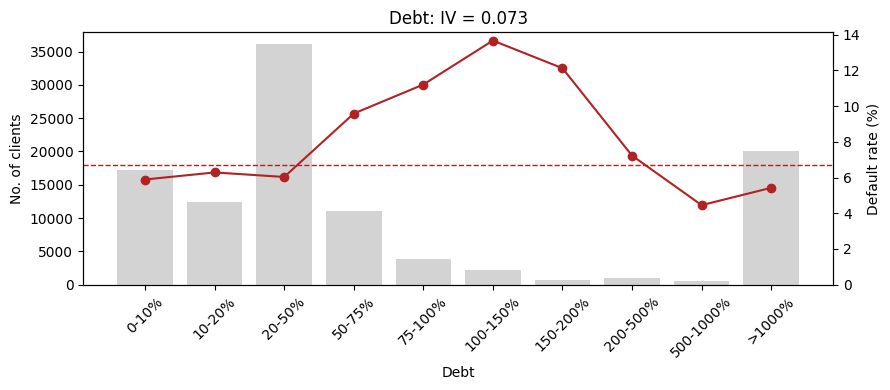


Income


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
Income,,,,,,,
0-1k,3385,170,0.050,0.033,0.024,0.301,0.003
1-2k,5094,542,0.106,0.046,0.077,-0.509,0.016
2-4k,19884,1830,0.092,0.184,0.261,-0.347,0.027
4-6k,20140,1496,0.074,0.190,0.213,-0.114,0.003
6-8k,13774,821,0.060,0.132,0.117,0.122,0.002
8-10k,9237,473,0.051,0.089,0.067,0.282,0.006
10-15k,9097,378,0.042,0.089,0.054,0.501,0.018
15-20k,2237,96,0.043,0.022,0.014,0.463,0.004
20-50k,1222,63,0.052,0.012,0.009,0.268,0.001


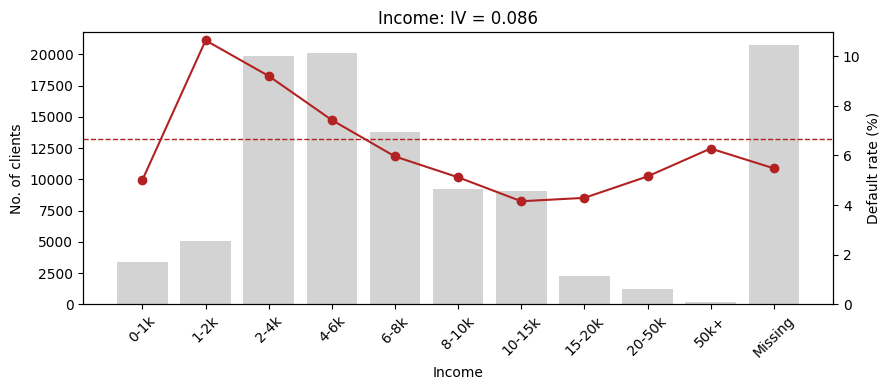


OpenCred


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
OpenCred,,,,,,,
0-5,32476,2742,0.084,0.303,0.391,-0.253,0.022
6-10,42300,2367,0.056,0.408,0.337,0.189,0.013
11-15,20498,1242,0.061,0.197,0.177,0.104,0.002
16-20,6968,475,0.068,0.066,0.068,-0.022,0.000
21-25,1952,131,0.067,0.019,0.019,-0.008,0.000
26+,806,61,0.076,0.008,0.009,-0.141,0.000


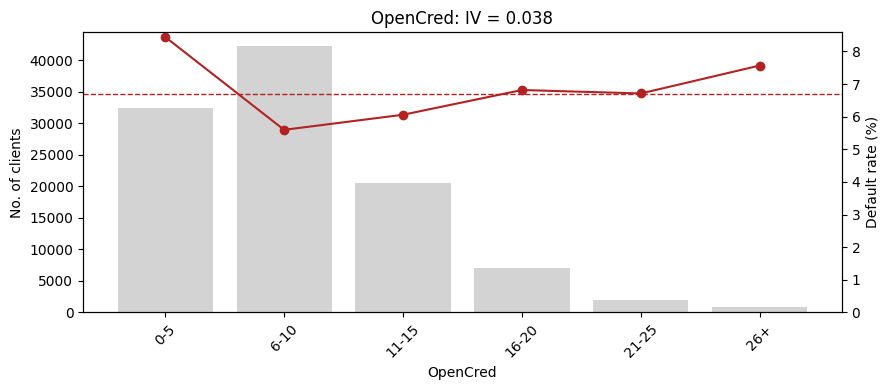


Late90


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
Late90,,,,,,,
0,99103,4558,0.046,0.965,0.649,0.396,0.125
1,3723,1261,0.339,0.025,0.180,-1.967,0.304
2,1094,535,0.489,0.006,0.076,-2.592,0.183
3,472,275,0.583,0.002,0.039,-2.969,0.111
4,218,153,0.702,0.001,0.022,-3.488,0.074
5-20,208,137,0.659,0.001,0.020,-3.290,0.062
96/98,182,99,0.544,0.001,0.014,-2.812,0.037


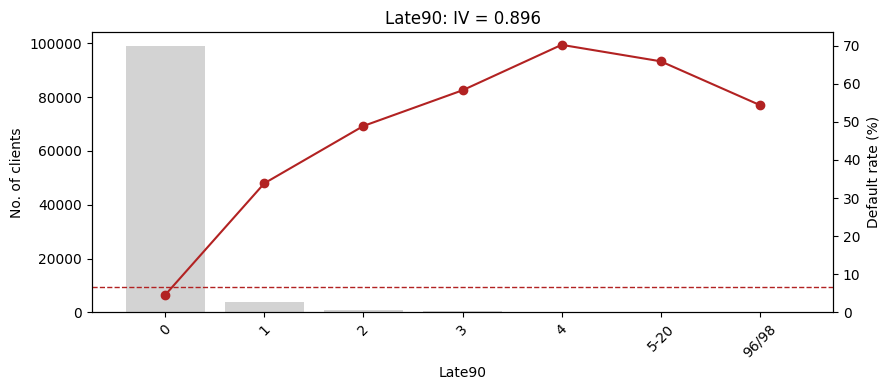


RealEstate


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
RealEstate,,,,,,,
0,39193,3255,0.083,0.367,0.464,-0.235,0.023
1,36731,1919,0.052,0.355,0.273,0.262,0.021
2,22106,1240,0.056,0.213,0.177,0.186,0.007
3,4426,315,0.071,0.042,0.045,-0.069,0.000
4+,2544,289,0.114,0.023,0.041,-0.583,0.011


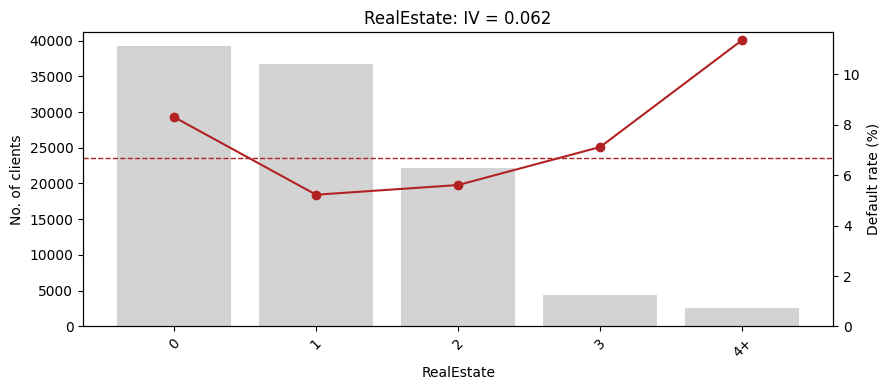


Late60_89


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
Late60_89,,,,,,,
0,99662,5072,0.051,0.965,0.723,0.289,0.070
1,4049,1262,0.312,0.028,0.180,-1.844,0.279
2,767,383,0.499,0.004,0.055,-2.634,0.134
3,222,124,0.559,0.001,0.018,-2.871,0.048
4,74,49,0.662,0.000,0.007,-3.300,0.022
5-20,44,29,0.659,0.000,0.004,-3.280,0.013
96/98,182,99,0.544,0.001,0.014,-2.812,0.037


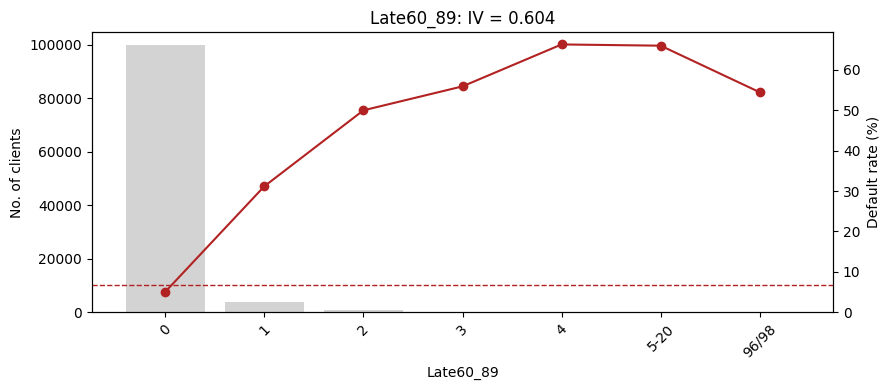


No.Dep


,n_clients,n_default,default_rate,pct_good,pct_bad,woe,iv
No.Dep,,,,,,,
0,60782,3580,0.059,0.584,0.510,0.135,0.010
1,18498,1366,0.074,0.175,0.195,-0.108,0.002
2,13644,1102,0.081,0.128,0.157,-0.205,0.006
3,6647,592,0.089,0.062,0.084,-0.312,0.007
4,2015,194,0.096,0.019,0.028,-0.399,0.004
5,524,51,0.097,0.005,0.007,-0.418,0.001
6+,169,20,0.118,0.002,0.003,-0.649,0.001
Missing,2721,113,0.042,0.027,0.016,0.498,0.005


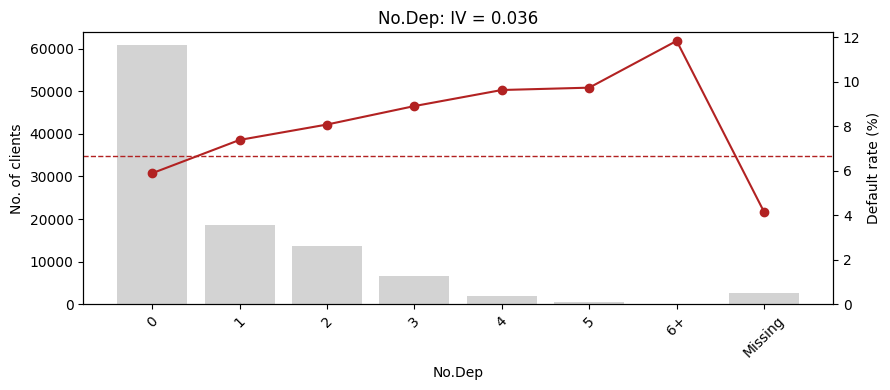

In [18]:
# One table and one plot per variable
bin_tables = {}

for column, spec in BINS.items():
    table = eda_utils.bin_table(train, column, spec['bins'], spec['labels'])
    bin_tables[column] = table

    print(f'\n{column}')
    display(table.round(3))
    eda_utils.plot_bin_table(table, column)
    plt.show()

*Notes:*
- **Util:** risk rises steadily with utilisation, from 1.8% (0–10%) to 44% (150–200%),
  then falls for the extreme values (31% for 200–500% and 10% for >500%). The extreme
  values are not the riskiest clients, which supports treating them as recording
  errors. The main increase happens between 20–50% (4.9%) and 50–75% (10.5%).
- **Age:** risk peaks at 26–30 (11.4%) and then falls steadily with age, down to 2.4%
  for clients over 70.
- **Late-payment variables:** risk rises with the number of late payments in all three,
  reaching 45–70% in the highest real counts. The special codes (`96/98`) have a
  default rate of 54.4%, similar to that of clients with 4 or more late payments. Some high bins are small
  (e.g. only 44 clients in `5-20` for Late60_89), so their rates are less stable.
- **Debt:** risk is almost flat (~6%) for most bins and only rises between 50% and
  200% (up to 13.7%). The `>1000%` bin holds 20,135 clients, mostly those without
  income, with a below-average rate (5.4%).
- **Income:** risk falls as income rises, from 10.6% (1–2k) to 4.2% (10–15k). The
  `0-1k` bin is an exception, with a below-average rate (5.0%). The `Missing` bin also
  has a below-average rate (5.5%).
- **RealEstate:** U-shaped risk: 8.3% for clients with no real estate loan, about 5.5%
  for 1–2 loans and 11.4% for 4 or more.
- **OpenCred and No.Dep:** weak effects. Clients with few open credit lines (0–5) are
  slightly riskier, and risk increases slightly with the number of dependents.

## 5. Information Value

IV summarises, in a single number, how well a variable separates good payers from
defaulters. WoE convention used here: `WoE = ln(% goods / % bads)`, so a negative
WoE means a riskier bin. The IV uses the same bins as Section 4.

For a full explanation, see [WoE and IV explained](../notes/woe_iv_explained.md).

| IV | Predictive power |
|---|---|
| < 0.02 | not useful |
| 0.02 – 0.10 | weak |
| 0.10 – 0.30 | medium |
| 0.30 – 0.50 | strong |
| > 0.50 | suspicious: check for leakage or overly fine bins |

In [19]:
iv = eda_utils.iv_summary(train, BINS)
iv

,variable,iv,strength
0,Util,1.139846,suspicious
1,Late90,0.896098,suspicious
2,Late30_59,0.743316,suspicious
3,Late60_89,0.604288,suspicious
4,Age,0.224720,medium
5,Income,0.085584,weak
6,Debt,0.073118,weak
7,RealEstate,0.061783,weak
8,OpenCred,0.037586,weak
9,No.Dep,0.035877,weak


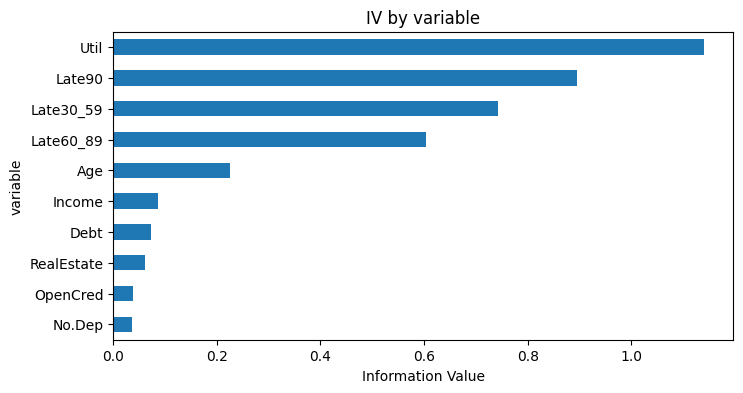

In [20]:
iv.plot(x='variable', y='iv', kind='barh', legend=False, figsize=(8, 4))
plt.gca().invert_yaxis()
plt.xlabel('Information Value')
plt.title('IV by variable')
plt.show()

*Notes:*
- Four variables have IV above 0.5: Util (1.14), Late90 (0.90), Late30_59 (0.74) and
  Late60_89 (0.60). This is expected and not leakage: utilisation and past
  delinquency are known at the time of the credit decision and are strong predictors
  of future default.
- Age has medium predictive power (0.22).
- Income, Debt, RealEstate, OpenCred and No.Dep are weak (between 0.04 and 0.09).
  They may still add information in a multivariate model.
- IV is univariate: a high IV for the three late-payment variables does not mean they
  add information together (see Section 6). IV also depends on the bins used.

## 6. Correlation and redundancy

Spearman correlation is used because it captures monotonic relationships and is
robust to outliers. Pairs with absolute correlation above 0.4 are listed.

------------------------------------------------------------------------------------------------------------------------------------------------------
Correlation analysis: (Spearman's method)
             Default      Util       Age  Late30_59      Debt    Income  OpenCred    Late90  RealEstate  Late60_89    No.Dep
Default     1.000000  0.240495 -0.113173   0.253750  0.019657 -0.066102 -0.040295  0.344993   -0.032883   0.277761  0.044722
Util        0.240495  1.000000 -0.276388   0.238835  0.075744 -0.075729 -0.087086  0.239965   -0.027906   0.188872  0.116457
Age        -0.113173 -0.276388  1.000000  -0.092302  0.032042  0.131293  0.159190 -0.101897    0.054930  -0.082595 -0.228103
Late30_59   0.253750  0.238835 -0.092302   1.000000  0.039096 -0.015862  0.062320  0.256491    0.023530   0.283692  0.072663
Debt        0.019657  0.075744  0.032042   0.039096  1.000000 -0.127376  0.229116 -0.032186    0.401952   0.000622 -0.036417
Income     -0.066102 -0.075729  0.131293  -0.015862 -0.12

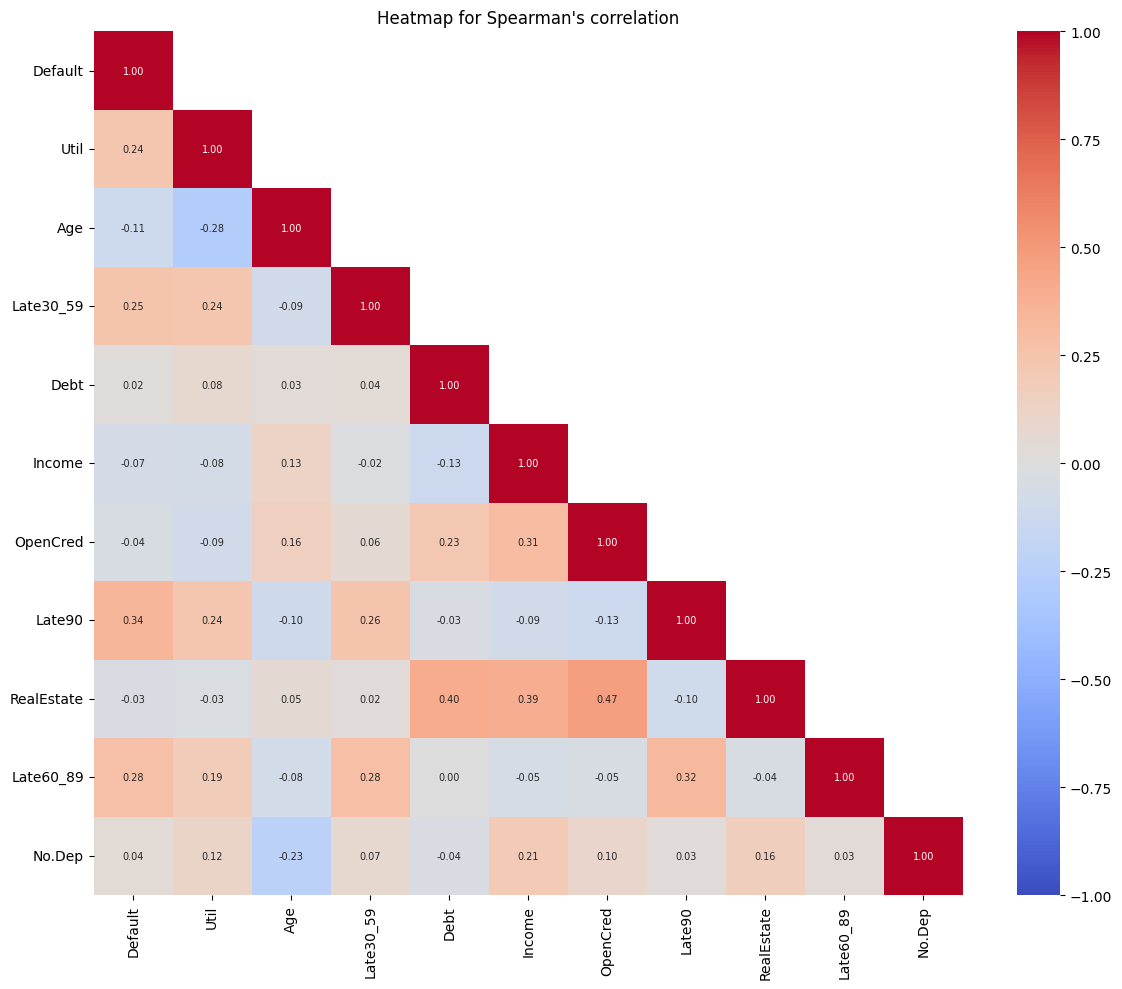

In [21]:
eda_utils.correlation_analysis(train)
plt.show()

*Notes:*
- The three late-payment variables are only moderately correlated with each other
  (Spearman between 0.26 and 0.32): most clients have zero in all of them, and clients
  who are late tend to be late in a single horizon. They are less redundant than
  expected.
- The only pairs above 0.4 are RealEstate–OpenCred (0.47) and RealEstate–Debt (0.40),
  with RealEstate–Income just below (0.39). These variables describe the size of the
  client's credit profile.
- Late90 has the highest correlation with Default (0.34), followed by Late60_89 (0.28),
  Late30_59 (0.25) and Util (0.24). Util ranks first by IV because IV also captures its
  non-monotonic shape, which a rank correlation does not.

## 7. Summary

- **Target:** the training split has 105,000 clients and a default rate of 6.68%.
- **Duplicates:** 609 exact duplicate rows (0.41%) in the raw data, kept.
- **Missing values:** Income is missing for 19.7% of the clients and No.Dep for 2.6%.
  All rows with missing No.Dep also have missing Income. These clients have a lower
  default rate (5.5% vs 7.0%), so missingness is informative, although the effect is
  small (IV of the `Missing` bin below 0.01).
- **Special codes:** 96 and 98 appear in the same 182 rows for the three late-payment
  variables. These rows have a default rate of 54.4%.
- **Extreme values:** Util has a small group of implausible values (0.16% above 10) with
  a risk close to the average, likely recording errors. Debt mixes two measures: a
  ratio for clients with income and an amount for clients without income (92.6% of the
  clients with Debt > 10 have missing income).
- **Risk patterns:** risk increases with utilisation and with late payments, and
  decreases with age. RealEstate shows a U-shape.
- **IV ranking:** Util and the three late-payment variables are the strongest, followed
  by Age. The other variables are weak.
- **Redundancy:** the late-payment variables are only moderately correlated with each
  other. The only strong pairs involve RealEstate (with OpenCred and Debt).
- **Implications for modelling:** based on these findings, the processing step applies
  the following treatments (all statistics are computed on the training split only):
  - **Missing income:** a flag for missing Income (`IncomeMissing`), with the values
    imputed by the median, which is robust to the long right tail of Income. The flag
    keeps the missingness signal and also marks the clients for whom Debt is an amount
    rather than a ratio. It covers the missing No.Dep rows as well.
  - **Special codes:** a flag for the codes 96/98 (`SpecialCode`), with the codes
    replaced by the median of each late-payment variable (0). This is done before
    computing `AnyLate`, `TotalLate` and `LateScore`, so the codes are not read as
    real counts; their high risk (54.4% default rate) is carried by the flag.
  - **Invalid utilisation:** values above 10 are implausible as a ratio. They are
    replaced by the highest valid value and marked with a flag (`UtilInvalid`), so
    the model can learn the risk of this group (about 10%) separately. This is done
    before computing `UtilAbove100`.
  - **Debt:** it is only a true ratio when income is reported, which should be kept in
    mind when interpreting it, together with `IncomeMissing`.